# Elegir una combinación antes de que llegue su objetivo

**Pregunta:** ¿Pueden los pronósticos históricos completos seleccionar una combinación más útil sin permitir que el objetivo final elija sus parámetros?

## Objetivos

Esta lección ejecuta ContextMemoryCV y ValidationMix, examina su información disponible y compara exactitud puntual con calidad de intervalos. La regla ContextMemory fija tiene un resultado medio ligeramente desfavorable frente a su ablación de recencia. Ese resultado sigue siendo válido para esa configuración. Motiva otro algoritmo, identificado explícitamente, en lugar de cambiar un número publicado o seleccionar solo ejemplos exitosos. La validación temporal es el mecanismo adicional: los parámetros se eligen con bloques anteriores cuyos objetivos ya se conocían al emitir el pronóstico de validación.

Las variantes conservan cinco expertos y las mismas características contextuales. ContextMemoryCV selecciona contracción y temperatura; ValidationMix considera además apilamiento convexo regularizado. Inspeccionaremos un caso generado con cambios de nivel, verificaremos disponibilidad completa de objetivos históricos, ejercitaremos la alternativa sin memoria suficiente y probaremos un cambio de unidades. Después reproduciremos ambos métodos sobre los quince casos de desarrollo e inspeccionaremos las colecciones semanales y mensuales evaluadas separadamente. Un pronóstico puntual útil y un intervalo de incertidumbre útil son resultados distintos.

## Preparación

Utilice el entorno declarado de cuadernos. Reproduzca sus dependencias directas exactas antes de ejecutar la lección:

```sh
python -m pip install numpy==2.4.6 scipy==1.15.3 matplotlib==3.10.8 statsforecast==2.0.3
python -m pip install lightgbm==4.6.0 mlforecast==1.0.31 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.4.0
```

La celda imprime versiones instaladas para comparar el entorno con estos requisitos. Los datos ya están admitidos en el repositorio; ninguna solicitud de red oculta ni conjunto sustituto participa en el ajuste. Comience con un núcleo limpio para impedir que un estado exploratorio previo cambie el resultado.


In [1]:
# Load the admitted contiguous prefix and identify exact runtime versions.
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import importlib.metadata
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.validated_combination import fit_validated
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
plt.rcParams.update({"figure.figsize": (8, 3.5), "figure.dpi": 95, "font.size": 10})
comparison = json.loads((root / "data/derived/reevaluation.json").read_text(encoding="utf-8"))
case = next(c for c in comparison["cases"] if c["case_id"] == "BRKV_level_shift")
history = np.array(case["history"])
actual = np.array(case["actual"])
m, h = case["seasonality"], case["horizon"]
print("History, horizon, seasonality:", len(history), h, m)
for package in ["numpy", "scipy", "matplotlib", "statsforecast", "lightgbm",
                "mlforecast", "nbformat", "nbclient", "ipykernel"]:
    print(package, importlib.metadata.version(package))


History, horizon, seasonality: 288 12 12
numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Datos

El prefijo disponible y los objetivos finales provienen de la comparación corregida con historia contigua. Los arreglos reducidos para visualización no se usan para ajustar. El ejemplo de cambios de nivel hace plausible que varíe la competencia, pero su generador no informa al algoritmo dónde cambió el proceso. El bloque final se carga solo para puntuar después. Ninguna llamada de ajuste recibe ese arreglo. Los inventarios externos constituyen otros experimentos, con horizonte, período estacional, exclusiones y hashes propios.

## Método

La memoria contiene hasta doce orígenes históricos completos. Para una consulta interna en v, un origen o es elegible para entrenar solo si o + H no supera v. Se exigen tres bloques completos. Las puntuaciones promedian errores absolutos escalados sobre bloques históricos posteriores. Esto es más estricto que exigir que el origen preceda a la consulta: un objetivo largo puede solaparse con una consulta posterior aunque su inicio sea anterior.

In [2]:
# Select contextual parameters using complete earlier target blocks.
context_cv = fit_validated(history, m, h, stacking=False)
recency = fit_context_memory(history, m, h, mode="recency")
print("ContextMemoryCV selected:", context_cv.selected)
print("Historical validation blocks:", len(context_cv.validation_splits))
for split in context_cv.validation_splits:
    print(split["query"], max(context_cv.origins[j] + h for j in split["train"]))
print("Every inner training target is complete at its query.")


ContextMemoryCV selected: ('context', 1.0, 0.15)
Historical validation blocks: 9
98 88
120 110
142 132
165 154
187 177
209 199
231 221
253 243
276 265
Every inner training target is complete at its query.


Contracción contextual uno elimina el núcleo de contexto. La temperatura controla cuánto cambia la asignación de expertos al variar su competencia estimada. Seleccionar una configuración de la familia contextual no demuestra por sí solo un beneficio de la similitud contextual. RecencyMean y EqualMean son candidatos explícitos, y un piso uniforme del cinco por ciento limita la concentración. La familia finita se fijó antes de calcular los nuevos resultados externos. No se amplía después de inspeccionar un objetivo externo difícil.

ValidationMix añade otro objetivo de ajuste. Elige pesos no negativos que suman uno para minimizar error cuadrático histórico normalizado y una penalización hacia pesos iguales. Cinco expertos permiten enumerar todos los conjuntos activos no vacíos. La selección sigue usando error absoluto reservado temporalmente. Se distinguen el objetivo de ajuste y la medida de selección; ninguno observa el objetivo final.

In [3]:
# Compare the extended finite candidate family and inspect its allocations.
validated = fit_validated(history, m, h, stacking=True)
print("ValidationMix selected:", validated.selected)
ranked = sorted(validated.candidates, key=lambda c: c["mean_validation_mae_scaled"])
for row in ranked[:4]:
    print(row["configuration"], round(row["mean_validation_mae_scaled"], 6))
print("Smallest weight:", round(float(validated.weights.min()), 6))
print("Total allocation:", round(float(validated.weights.sum()), 6))


ValidationMix selected: ('context', 1.0, 0.15)
('context', 1.0, 0.15) 1.119732
('context', 0.5, 0.15) 1.130505
('equal', 0.0, 1.0) 1.135695
('context', 0.0, 0.15) 1.154115
Smallest weight: 0.023651
Total allocation: 1.0


El cálculo siguiente elimina suficiente historia para que la validación no esté disponible. Compara la trayectoria con la alternativa de recencia especificada, de modo que la falta de una estimación no se confunda con un candidato exitoso inventado.

In [4]:
# Exercise the no-validation fallback without consulting future targets.
short = history[:30]
fallback = fit_validated(short, m, h)
short_recency = fit_context_memory(short, m, h, mode="recency")
print("Validation blocks:", len(fallback.validation_splits), "Rule:", fallback.selected)
print("Difference from control:", round(float(np.max(abs(fallback.quantiles - short_recency.quantiles))), 8))
print("Insufficient validation uses the matching recency control.")


Validation blocks: 0 Rule: ('recency', 1.0, 1.0)
Difference from control: 0.0
Insufficient validation uses the matching recency control.


El cálculo del prefijo corto ejercita una alternativa real, no un pronóstico de reemplazo inventado. Con poca memoria completa no se puede estimar una puntuación de validación. El algoritmo retorna la regla especificada de recencia, que puede usar pesos iguales si no existen orígenes elegibles. Elegir silenciosamente un experto exitoso utilizando el objetivo final cargado violaría este contrato.

Cambiar unidades no debería alterar la competencia solo porque una serie se mida en otra escala positiva. El cálculo siguiente aplica un desplazamiento y una escala comunes lejos de umbrales de degeneración numérica. Compara pronósticos transformados con la transformación del pronóstico original. Verifica una propiedad estructural de la construcción, no exactitud predictiva en otro conjunto de datos.

In [5]:
# Refit after a positive change of units and common location shift.
changed_units = fit_validated(2 * history + 7, m, h)
unit_difference = np.max(abs(changed_units.quantiles - (2 * validated.quantiles + 7)))
print("Unit-transform maximum difference:", f"{unit_difference:.8f}")
print("Positive unit change and common shift preserve the forecast transformation.")


Unit-transform maximum difference: 0.00000000
Positive unit change and common shift preserve the forecast transformation.


Se retrocede la consulta un bloque y se ajusta únicamente con el prefijo restante. El extremo impreso hace visible el límite de información. El gráfico compara después los pesos ajustados en la consulta original, sin utilizar objetivos finales para seleccionar una explicación conveniente.

All earlier targets available: True
Earlier query prefix: 276
Latest remembered target endpoint: 276


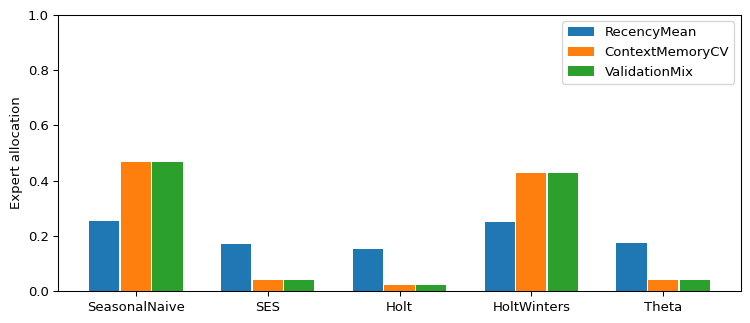

In [6]:
# Refit an earlier information cutoff, then inspect original-query weights.
earlier = fit_validated(history[:-h], m, h)
print("All earlier targets available:", all(o + h <= len(history) - h for o in earlier.origins))
print("Earlier query prefix:", len(history) - h)
print("Latest remembered target endpoint:", max(earlier.origins) + h)
fig, ax = plt.subplots()
positions = np.arange(5)
for offset, label, fit in [(-0.24, "RecencyMean", recency),
                           (0, "ContextMemoryCV", context_cv),
                           (0.24, "ValidationMix", validated)]:
    ax.bar(positions + offset, fit.weights, width=0.23, label=label)
ax.set_xticks(positions, ["SeasonalNaive", "SES", "Holt", "HoltWinters", "Theta"])
ax.set(ylabel="Expert allocation", ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()


## Comparación

Las barras distintas muestran asignaciones de pronóstico diferentes. No atribuyen una reducción de error a una característica ni exclusivamente al núcleo contextual. La familia seleccionada cambia temperatura y contracción además de ponderación contextual, mientras ValidationMix puede elegir apilamiento. Una afirmación futura sobre componentes necesitaría una ablación equivalente basada en validación. El cálculo del prefijo anterior muestra además que los extremos históricos se mueven con la consulta: la memoria se reconstruye con lo disponible en ese corte. Los orígenes no son réplicas independientes, porque sus historias de ajuste se solapan.

## Evidencia

Ahora ejecutamos ambas variantes nuevas sobre el prefijo original de cada caso. Se conservan los quince bloques. La comparación informa sobre estas configuraciones, pero los casos ya fueron examinados durante el desarrollo y no constituyen confirmación externa nueva. Los documentos públicos proporcionan una comprobación numérica sin reemplazar estas llamadas de ajuste.

In [7]:
# Execute both variants on every original contiguous development prefix.
development = {"ContextMemoryCV": [], "ValidationMix": []}
for c in comparison["cases"]:
    prefix = np.array(c["history"])
    target = np.array(c["actual"])
    for name in development:
        fit = fit_validated(prefix, c["seasonality"], c["horizon"], stacking=name == "ValidationMix")
        q = fit.quantiles
        score = metrics(prefix, target, q[:, 1], q[:, 0], q[:, 2], c["seasonality"])
        development[name].append(score["mase"])
study = json.loads((root / "data/derived/validated-combinations.json").read_text(encoding="utf-8"))
selected = next(c for c in study["cohorts"] if c["id"] == "selected_cases")
for name, scores in development.items():
    stored = next(r["mase"] for r in selected["summary"] if r["name"] == name)
    assert np.isclose(np.mean(scores), stored, rtol=1e-10, atol=1e-10)
    print(name, "mean development MASE", f"{np.mean(scores):.4f}")


ContextMemoryCV mean development MASE 1.3974
ValidationMix mean development MASE 1.4031


La segunda figura lee resúmenes externos admitidos separadamente. Cada panel compara métodos sobre las mismas series elegibles. Separar los paneles mantiene visible al comparador estadístico mensual, en lugar de ocultarlo en un promedio general dominado por otra colección.

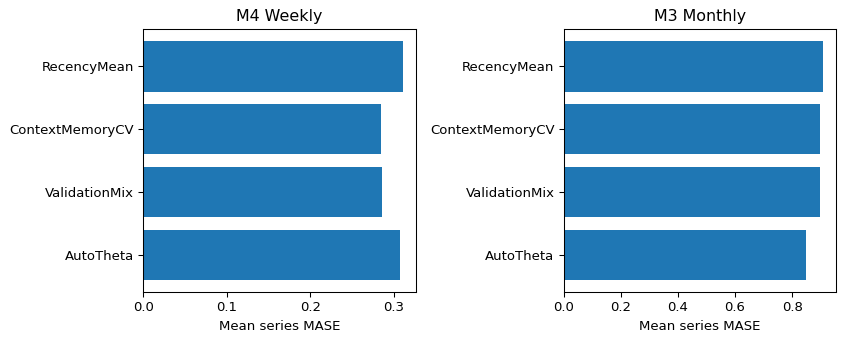

In [8]:
# Compare external collections separately, retaining the statistical comparator.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
names = ["RecencyMean", "ContextMemoryCV", "ValidationMix", "AutoTheta"]
for ax, dataset in zip(axes, ["m4_weekly", "m3_monthly"]):
    cohort = next(c for c in study["cohorts"] if c["id"] == dataset)
    values = [next(r["mase"] for r in cohort["summary"] if r["name"] == n) for n in names]
    ax.barh(names, values)
    ax.invert_yaxis()
    ax.set(title=cohort["name"], xlabel="Mean series MASE")
fig.tight_layout()
plt.show()


## Resultados

**Respuesta:** Los MASE medios de desarrollo reproducidos son 1.3974 para ContextMemoryCV y 1.4031 para ValidationMix. Las variantes también mejoran el error puntual frente a RecencyMean en ambas colecciones externas admitidas. AutoTheta mantiene menor error puntual mensual y mejores puntuaciones de intervalos en ambas. La atribución contextual y la incertidumbre calibrada siguen sin resolverse.

La tabla externa contabiliza cada identidad de origen. Sesenta y cinco series semanales tienen historia insuficiente para el protocolo estacional y de orígenes fijado; seis identidades mensuales son duplicados exactos. Se promedian orígenes elegibles por serie y después se asigna igual peso a cada serie dentro de su colección. Las variantes nuevas reducen MASE medio frente al control de recencia en ambas colecciones admitidas. Sin embargo, AutoTheta tiene menor error puntual mensual y menor puntuación de intervalos en ambas. La figura se interpreta por colección y comparador, no como clasificación universal ni resultado oficial de la competición M4.

Los extremos gaussianos de las combinaciones son amplios. Cobertura por encima del nivel nominal no es automáticamente útil al considerar amplitud y penalizaciones por objetivos fuera del intervalo. Los quince casos originales muestran esa distinción: las variantes nuevas mejoran error puntual y empeoran MSIS frente a RecencyMean. Ni los pesos convexos ni seleccionar parámetros por error puntual calibran el intervalo. Un método futuro de incertidumbre necesita protocolo temporal y evaluación reservada propios.

## Resumen

Inspeccione qué candidato gana en la historia con cambios de nivel y si elimina el contexto. Explique por qué cambiar objetivos finales después del ajuste no puede cambiar legítimamente la configuración seleccionada. Diseñe una familia equivalente de validación solo con recencia antes de afirmar que el núcleo contextual causó una mejora. Si propone expertos adicionales o nuevos intervalos, identifique otra colección de confirmación antes de examinar sus resultados. Preserve los resultados anteriores en lugar de relatar configuraciones desfavorables como si nunca se hubiesen evaluado.

La mejora útil es acotada: una regla temporal fija produce mejores pronósticos puntuales empíricos que el comparador original de recencia sobre las colecciones admitidas. Conserva límites importantes en atribución a componentes, eficiencia de intervalos y generalización. Reproducir exige el entorno declarado, prefijos contiguos originales e inventarios identificados separadamente; un gráfico renderizado no establece esas condiciones por sí solo.

## Referencias

- [MASE y exactitud de pronósticos](https://doi.org/10.1016/j.ijforecast.2006.03.001).
- [FFORMA](https://doi.org/10.1016/j.ijforecast.2019.02.011).
- [Arbitrage of forecasting experts](https://doi.org/10.1007/s10994-018-05774-y).
- [Fuente M4 Weekly](https://doi.org/10.5281/zenodo.4656522).
- [Fuente M3 Monthly](https://doi.org/10.5281/zenodo.4656298).
